# Time Series - Seasonal ensembles

A `SeasonalEnsemble` treats **the years of a single series as members of an ensemble**. All years are drawn over the same calendar, which shows the seasonal cycle, how much it varies between years, and how one year compares with the others.

Covered here:

- Getting the ensemble from a series
- Highlighting a year
- Labels of the x axis
- Reducers and their dates
- Water years
- Monthly series and other time steps

```{seealso}
Check out the {doc}`Time Series - Ensembles <timeseries_10_ensemble>` tutorial first. Reducers, bands and highlights work the same way here.
```

## Notebook setup

For users running this tutorial as a Jupyter Notebook, this cell must be executed first:

In [1]:
import sys

# Install `plans` in `google.colab`.
# Use `pip install plans` for other environments.

if "google.colab" in sys.modules:
    import os
    os.system(f"{sys.executable} -m pip install -q plans")

from plans.datasets import RainSeries, TemperatureSeries

# This avoids warnings related to uninstalled fonts
import logging
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

## Get the ensemble from a series

Here is a synthetic daily temperature series of about 25 years, which stops in the middle of its last year. The `.get_seasonal_ensemble()` method splits it into one member per year, of the same type as the series. The series itself does not change:

In [2]:
ts = TemperatureSeries(name="Sim")
ts.generate(start="2000-01-01", end="2024-08-15", seed=1, inplace=True)

se = ts.get_seasonal_ensemble()
se.catalog[["name", "start", "end", "size"]].tail()

,name,start,end,size
20,2020,2000-01-01,2000-12-31,366
21,2021,2000-01-01,2000-12-31,365
22,2022,2000-01-01,2000-12-31,365
23,2023,2000-01-01,2000-12-31,365
24,2024,2000-01-01,2000-08-15,228


All members are on the same year, and 2000 is only a placeholder, chosen because it is a leap year. The incomplete year 2024 stays as a member and counts in the reducers where it has data.

The default view draws the years in the background, with the mean and a percentile band on top:

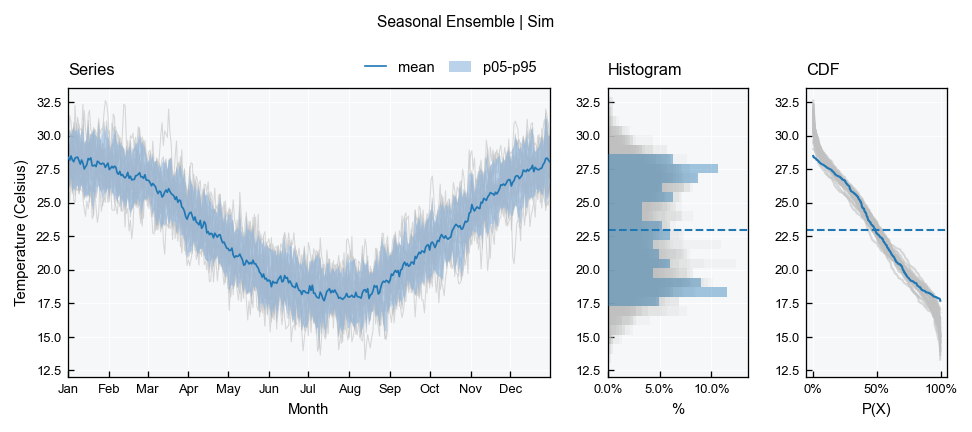

In [3]:
se.view()

## Highlight a year

Members are named by year, as strings, so `view_specs["highlight"]` picks one out. This is how to compare the current year with the previous ones:

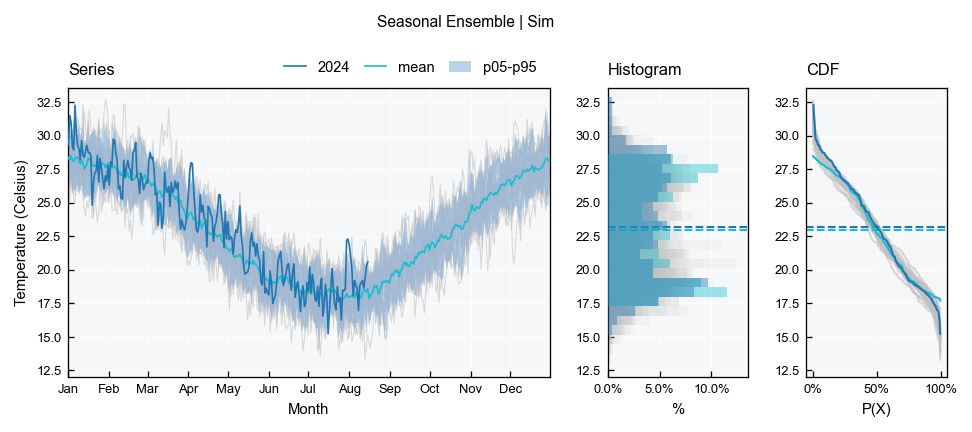

In [4]:
se.view_specs["highlight"] = ["2024"]
se.view()

To see the year against the bands alone, hide the other years with `view_specs["plot_background"]`:

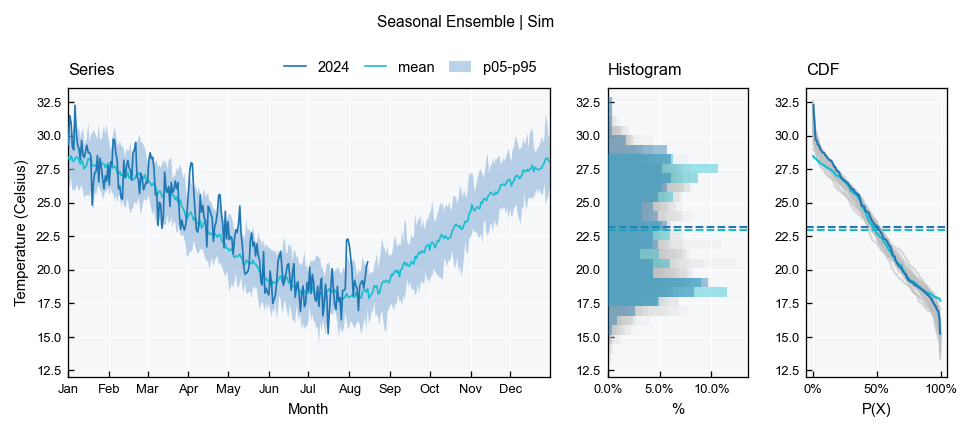

In [5]:
se.view_specs["plot_background"] = False
se.view()

## Labels of the x axis

The `xaxis` spec sets the labels, and the options are `month-alias` (the default), `month-letter`, `month` and `days`. For instance, the day of the year, with the `series-simple` layout:

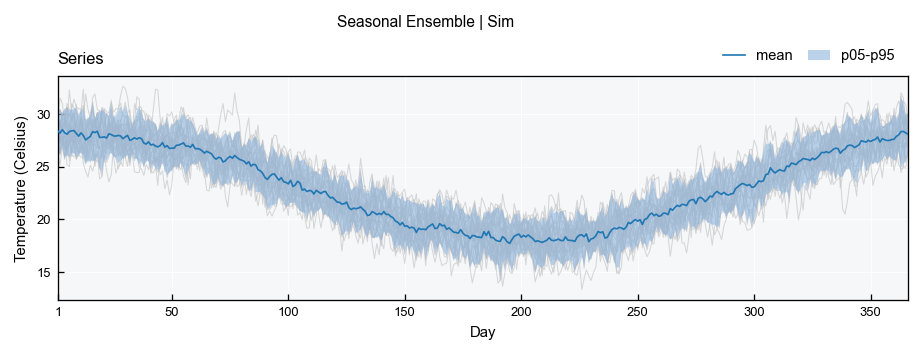

In [6]:
se.view_specs["highlight"] = None
se.view_specs["plot_background"] = True
se.view_specs["layout"] = "series-simple"
se.view_specs["xaxis"] = "days"
se.view()

Or the first letter of each month:

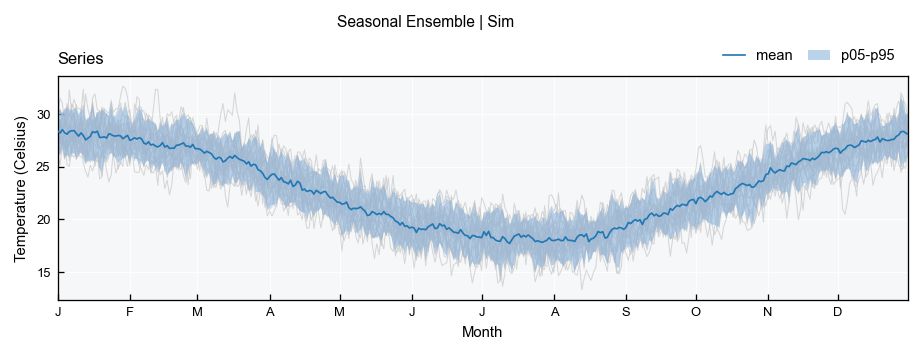

In [7]:
se.view_specs["xaxis"] = "month-letter"
se.view()

```{note}
The reference year is a leap year, so `days` always counts 29 Feb: 1 March is day 61, also for members that are not leap years.
```

## Reducers and their dates

Reducers work across years at each step, as in a `TimeSeriesEnsemble`. They return a `pandas.DataFrame` with the datetime and one column per statistic, named `{varalias}_{statistic}`. The mean of each calendar day over all years:

In [8]:
se.mean().head()

,datetime,TAS_mean
0,2000-01-01,28.383279
1,2000-01-02,28.169339
2,2000-01-03,28.492458
3,2000-01-04,28.207311
4,2000-01-05,28.063112


Percentiles are named by their value:

In [9]:
se.percentiles(values=[5, 50, 95]).head()

,datetime,TAS_p05,TAS_p50,TAS_p95
0,2000-01-01,26.451995,28.479368,30.061823
1,2000-01-02,26.127887,28.137300,30.397375
2,2000-01-03,26.961585,28.590795,30.043051
3,2000-01-04,25.828472,28.212592,30.307475
4,2000-01-05,26.087131,28.083328,30.631371


And `.stats()` gives a combined table, with `basic=True` to keep only the quartiles:

In [10]:
se.stats(basic=True).head()

,datetime,TAS_sum,TAS_mean,TAS_std,TAS_min,TAS_max,TAS_p25,TAS_p50,TAS_p75
0,2000-01-01,709.581970,28.383279,1.069638,26.345397,30.182454,27.879470,28.479368,29.236899
1,2000-01-02,704.233486,28.169339,1.428355,25.111814,31.497556,27.255070,28.137300,28.902733
2,2000-01-03,712.311445,28.492458,1.139475,26.680771,31.003125,27.541150,28.590795,29.585939
3,2000-01-04,705.182779,28.207311,1.446431,25.684764,30.448555,27.031522,28.212592,29.382703
4,2000-01-05,701.577811,28.063112,1.471101,25.210212,30.984469,26.806353,28.083328,28.943544


The dates are on the reference year, so the row below is the average of all years on 5 March, and not a value from the year 2000:

In [11]:
df = se.mean()
df[df["datetime"] == "2000-03-05"]

,datetime,TAS_mean
64,2000-03-05,26.441786


To use these results with real dates, for instance to join them with the original series, use the month and day instead of the full date:

In [12]:
df["month_day"] = df["datetime"].dt.strftime("%m-%d")
df.head()

,datetime,TAS_mean,month_day
0,2000-01-01,28.383279,01-01
1,2000-01-02,28.169339,01-02
2,2000-01-03,28.492458,01-03
3,2000-01-04,28.207311,01-04
4,2000-01-05,28.063112,01-05


`.get_reducer_series()` returns a reducer as a series of the same type, also on the reference year:

In [13]:
ts_mean = se.get_reducer_series(name="mean")
print(type(ts_mean).__name__)
ts_mean.data.head()

TemperatureSeries


,datetime,tas
0,2000-01-01,28.383279
1,2000-01-02,28.169339
2,2000-01-03,28.492458
3,2000-01-04,28.207311
4,2000-01-05,28.063112


```{note}
Only leap years have a value on 29 Feb, so the reducers of that step use fewer members. With few leap years in the record, this can show as a one-day jump in the bands.
```

## Water years

The `year_start` parameter sets the first month of the year. Members then hold two calendar years, and their names show both:

In [14]:
se_water = ts.get_seasonal_ensemble(year_start=10)
list(se_water.collection)[:3]

['1999-00', '2000-01', '2001-02']

The x axis starts on that month, and `days` counts from the start of the water year:

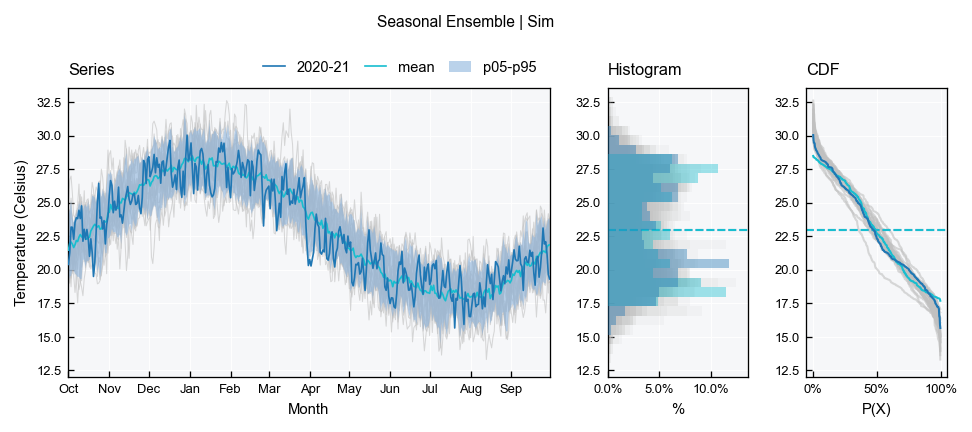

In [15]:
se_water.view_specs["highlight"] = ["2020-21"]
se_water.view()

## Monthly series

With monthly data this is the classical seasonal plot. Monthly dates are moved to the first day of the month, so it does not matter which day of the month the data use:

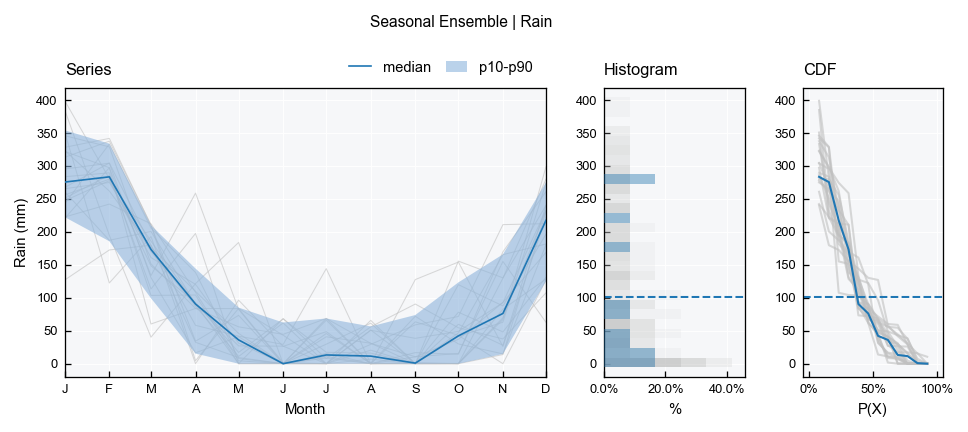

In [16]:
rain = RainSeries(name="Rain")
rain.generate(start="2000-01-01", end="2019-12-31", freq="MS", seed=1, inplace=True)

se_rain = rain.get_seasonal_ensemble()
se_rain.view_specs["reducers"] = ["median"]
se_rain.view_specs["bands"] = [[10, 90]]
se_rain.view_specs["xaxis"] = "month-letter"
se_rain.view()

## Other time steps

The ensemble works with monthly, daily and shorter steps, because these steps fall on the same calendar positions every year. Other steps, like weekly data, do not, so each date would hold only a few members. These raise an error:

In [17]:
weekly = TemperatureSeries(name="Weekly")
weekly.generate(start="2000-01-01", end="2004-12-31", freq="7D", seed=1, inplace=True)

try:
    weekly.get_seasonal_ensemble()
except ValueError as e:
    print(e)

Time step of 7 days 00:00:00 does not repeat each year. Use a monthly, daily or shorter step


## Recap

- `.get_seasonal_ensemble()` makes one member per year from a series, with incomplete years included.
- Reducers, bands, `highlight` and `plot_background` work as in a `TimeSeriesEnsemble`, and members are named by year.
- `view_specs["xaxis"]` sets the labels: `month-alias`, `month-letter`, `month` or `days`.
- Reducers return a `pandas.DataFrame` with one row per step of the year. Their dates, like those of the members, are placeholders of a leap reference year.
- `year_start` sets the first month, for water years.
- Time steps must repeat each year: monthly, daily or shorter.